In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

from pathlib import Path

In [2]:
# Paths and device

DATASET_DIR = Path("../dataset")

TRAIN_DIR = DATASET_DIR / "train"
VAL_DIR = DATASET_DIR / "validation"

device = torch.device("cpu")

print("Device:", device)
print("Train directory:", TRAIN_DIR.resolve())
print("Validation directory:", VAL_DIR.resolve())

Device: cpu
Train directory: D:\deepfake\dataset\train
Validation directory: D:\deepfake\dataset\validation


In [3]:
# Define transforms

IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [4]:
# Load datasets

train_dataset = ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

val_dataset = ImageFolder(
    root=VAL_DIR,
    transform=val_transform
)

print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Classes: ['fake', 'real']
Class mapping: {'fake': 0, 'real': 1}
Training images: 1428
Validation images: 306


In [5]:
# DataLoaders

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 90
Validation batches: 20


In [6]:
# Load EfficientNet-B0

weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(weights=weights)

# Replace ImageNet classifier
in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    2
)

model = model.to(device)

print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)


In [7]:
# Freeze the feature extractor

for param in model.features.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 4010110
Trainable parameters: 2562


In [8]:
# Loss and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001
)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [9]:
# Test one forward pass

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

Input shape: torch.Size([16, 3, 224, 224])
Output shape: torch.Size([16, 2])
Labels shape: torch.Size([16])


In [10]:
# Create the training function

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [11]:
# Create validation function

def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Statistics
            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [12]:
# Configure training

EPOCHS = 5

best_val_accuracy = 0.0

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "efficientnet_b0_best.pth"

print("Epochs:", EPOCHS)
print("Best model path:", BEST_MODEL_PATH)

Epochs: 5
Best model path: ..\models\efficientnet_b0_best.pth


In [13]:
# Start training

for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")
    print("-" * 40)

    # Training
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validation
    val_loss, val_accuracy = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    # Save history
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")

    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")

    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        print("✓ Best model saved!")

print("\nTraining completed.")
print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")


Epoch [1/5]
----------------------------------------
Train Loss: 0.7044
Train Accuracy: 0.4881
Validation Loss: 0.6903
Validation Accuracy: 0.5556
✓ Best model saved!

Epoch [2/5]
----------------------------------------
Train Loss: 0.6885
Train Accuracy: 0.5364
Validation Loss: 0.6858
Validation Accuracy: 0.5392

Epoch [3/5]
----------------------------------------
Train Loss: 0.6814
Train Accuracy: 0.5560
Validation Loss: 0.6764
Validation Accuracy: 0.5817
✓ Best model saved!

Epoch [4/5]
----------------------------------------
Train Loss: 0.6659
Train Accuracy: 0.5938
Validation Loss: 0.6695
Validation Accuracy: 0.5882
✓ Best model saved!

Epoch [5/5]
----------------------------------------
Train Loss: 0.6647
Train Accuracy: 0.6008
Validation Loss: 0.6648
Validation Accuracy: 0.5784

Training completed.
Best Validation Accuracy: 0.5882


In [14]:
# Load the best saved model

# Load the best model saved during training
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

model = model.to(device)

print("Best model loaded successfully.")

Best model loaded successfully.


In [15]:
# Create the test dataset

TEST_DIR = DATASET_DIR / "test"

test_dataset = ImageFolder(
    root=TEST_DIR,
    transform=val_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Test classes:", test_dataset.classes)
print("Test class mapping:", test_dataset.class_to_idx)
print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))

Test classes: ['fake', 'real']
Test class mapping: {'fake': 0, 'real': 1}
Test images: 307
Test batches: 20


In [16]:
# Evaluate the model
model.eval()

correct = 0
total = 0

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

test_accuracy = correct / total

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 0.5668
Test Accuracy: 56.68%


In [17]:
# Classification Report

from sklearn.metrics import classification_report

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Fake", "Real"]
    )
)

              precision    recall  f1-score   support

        Fake       0.54      0.52      0.53       144
        Real       0.59      0.61      0.60       163

    accuracy                           0.57       307
   macro avg       0.56      0.56      0.56       307
weighted avg       0.57      0.57      0.57       307



Confusion Matrix:
[[75 69]
 [64 99]]


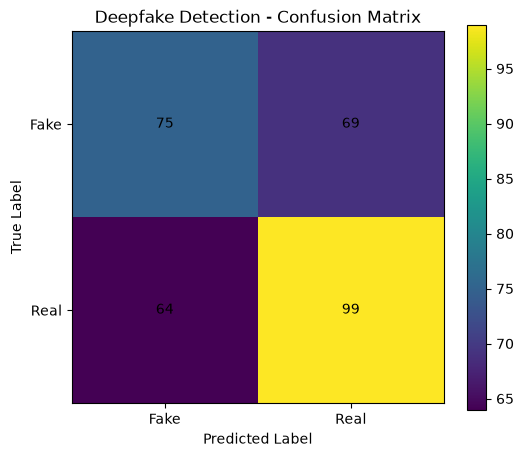

In [18]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Deepfake Detection - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    [0, 1],
    ["Fake", "Real"]
)

plt.yticks(
    [0, 1],
    ["Fake", "Real"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

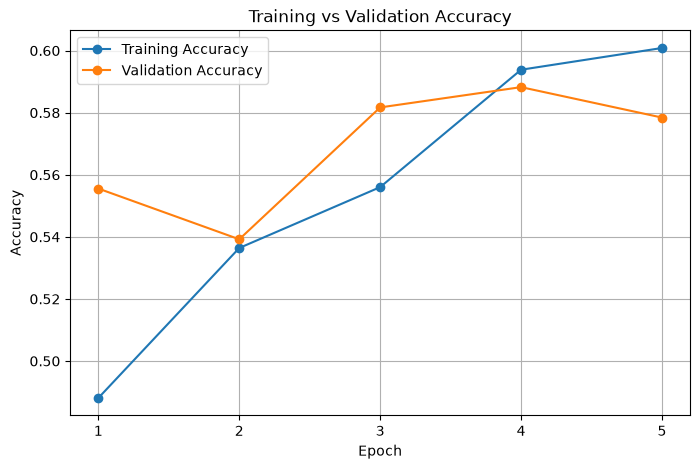

In [19]:
# Plot training and validation curves

import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

# Accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid()
plt.show()

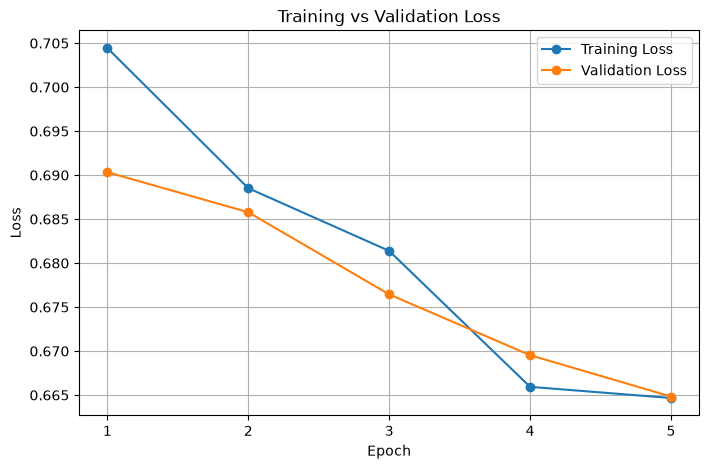

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid()
plt.show()

In [21]:
# Unfreeze the last 3 feature blocks


# Freeze the entire feature extractor first
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the last 3 feature blocks
for block in model.features[6:]:
    for param in block.parameters():
        param.requires_grad = True

# Keep classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

# Count parameters
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 4010110
Trainable parameters: 3158302


In [22]:
# Create a smaller learning rate

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.00001
)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 1e-05
    maximize: False
    weight_decay: 0
)


In [23]:
# Create separate fine-tuning history

FINE_TUNE_EPOCHS = 5

fine_train_losses = []
fine_train_accuracies = []

fine_val_losses = []
fine_val_accuracies = []

best_fine_val_accuracy = 0.0

FINE_TUNE_MODEL_PATH = MODEL_DIR / "efficientnet_b0_finetuned_best.pth"

print("Fine-tuning epochs:", FINE_TUNE_EPOCHS)
print("Model path:", FINE_TUNE_MODEL_PATH)

Fine-tuning epochs: 5
Model path: ..\models\efficientnet_b0_finetuned_best.pth


In [25]:
# Fine-tuning training loop

for epoch in range(FINE_TUNE_EPOCHS):

    print(f"\nFine-Tuning Epoch [{epoch + 1}/{FINE_TUNE_EPOCHS}]")
    print("-" * 50)

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    fine_train_losses.append(train_loss)
    fine_train_accuracies.append(train_accuracy)

    fine_val_losses.append(val_loss)
    fine_val_accuracies.append(val_accuracy)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")

    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")

    if val_accuracy > best_fine_val_accuracy:

        best_fine_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            FINE_TUNE_MODEL_PATH
        )

        print("✓ Best fine-tuned model saved!")

print("\nFine-tuning completed.")
print(
    f"Best Fine-Tuned Validation Accuracy: "
    f"{best_fine_val_accuracy:.4f}"
)


Fine-Tuning Epoch [1/5]
--------------------------------------------------
Train Loss: 0.6171
Train Accuracy: 0.6723
Validation Loss: 0.6296
Validation Accuracy: 0.6373
✓ Best fine-tuned model saved!

Fine-Tuning Epoch [2/5]
--------------------------------------------------
Train Loss: 0.6066
Train Accuracy: 0.6758
Validation Loss: 0.6187
Validation Accuracy: 0.6732
✓ Best fine-tuned model saved!

Fine-Tuning Epoch [3/5]
--------------------------------------------------
Train Loss: 0.5824
Train Accuracy: 0.7108
Validation Loss: 0.6141
Validation Accuracy: 0.6634

Fine-Tuning Epoch [4/5]
--------------------------------------------------
Train Loss: 0.5745
Train Accuracy: 0.7101
Validation Loss: 0.6017
Validation Accuracy: 0.6993
✓ Best fine-tuned model saved!

Fine-Tuning Epoch [5/5]
--------------------------------------------------
Train Loss: 0.5647
Train Accuracy: 0.7234
Validation Loss: 0.5991
Validation Accuracy: 0.6699

Fine-tuning completed.
Best Fine-Tuned Validation Accura

In [26]:
# Evaluate the fine-tuned model

model.load_state_dict(
    torch.load(
        FINE_TUNE_MODEL_PATH,
        map_location=device
    )
)

model = model.to(device)

print("Best fine-tuned model loaded.")

Best fine-tuned model loaded.


In [27]:
model.eval()

correct = 0
total = 0

fine_all_predictions = []
fine_all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        fine_all_predictions.extend(
            predictions.cpu().numpy()
        )

        fine_all_labels.extend(
            labels.cpu().numpy()
        )

fine_test_accuracy = correct / total

print(f"Fine-Tuned Test Accuracy: {fine_test_accuracy:.4f}")
print(f"Fine-Tuned Test Accuracy: {fine_test_accuracy * 100:.2f}%")

Fine-Tuned Test Accuracy: 0.6515
Fine-Tuned Test Accuracy: 65.15%


In [28]:
# Classification report

from sklearn.metrics import classification_report

print(
    classification_report(
        fine_all_labels,
        fine_all_predictions,
        target_names=["Fake", "Real"]
    )
)

              precision    recall  f1-score   support

        Fake       0.64      0.60      0.62       144
        Real       0.66      0.69      0.68       163

    accuracy                           0.65       307
   macro avg       0.65      0.65      0.65       307
weighted avg       0.65      0.65      0.65       307



Fine-Tuned Confusion Matrix:
[[ 87  57]
 [ 50 113]]


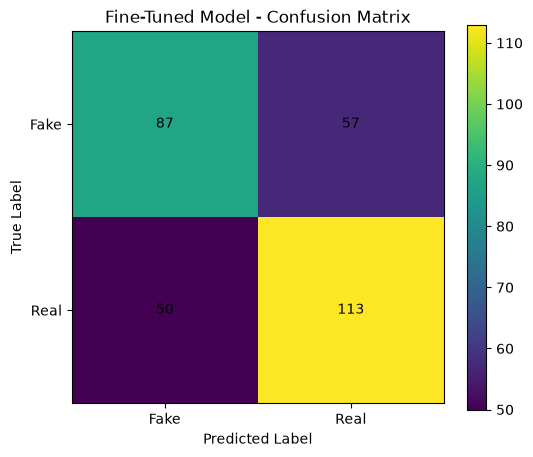

In [32]:
# Fine-tuned confusion matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

fine_cm = confusion_matrix(
    fine_all_labels,
    fine_all_predictions
)

print("Fine-Tuned Confusion Matrix:")
print(fine_cm)

plt.figure(figsize=(6, 5))

plt.imshow(fine_cm)

plt.title("Fine-Tuned Model - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    [0, 1],
    ["Fake", "Real"]
)

plt.yticks(
    [0, 1],
    ["Fake", "Real"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            fine_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

In [36]:
print("Fine train losses:", len(fine_train_losses))
print("Fine train accuracies:", len(fine_train_accuracies))
print("Fine validation losses:", len(fine_val_losses))
print("Fine validation accuracies:", len(fine_val_accuracies))

Fine train losses: 9
Fine train accuracies: 9
Fine validation losses: 9
Fine validation accuracies: 9


In [37]:
epochs_range = range(1, FINE_TUNE_EPOCHS + 1)

In [38]:
epochs_range = range(1, len(fine_train_accuracies) + 1)

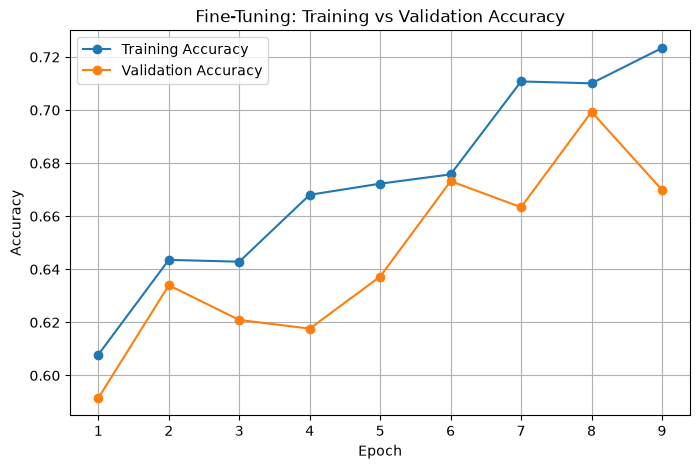

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    fine_train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    fine_val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fine-Tuning: Training vs Validation Accuracy")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid()

plt.show()

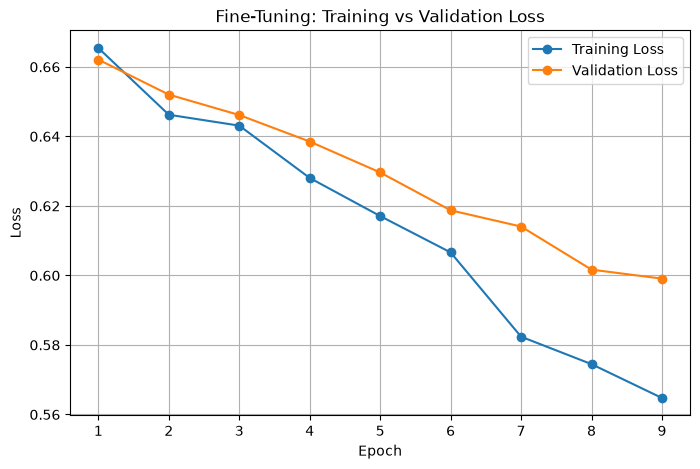

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    fine_train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    fine_val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine-Tuning: Training vs Validation Loss")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid()

plt.show()

In [41]:
from sklearn.metrics import classification_report

print(
    classification_report(
        fine_all_labels,
        fine_all_predictions,
        target_names=["Fake", "Real"]
    )
)

              precision    recall  f1-score   support

        Fake       0.64      0.60      0.62       144
        Real       0.66      0.69      0.68       163

    accuracy                           0.65       307
   macro avg       0.65      0.65      0.65       307
weighted avg       0.65      0.65      0.65       307



Fine-Tuned Confusion Matrix:
[[ 87  57]
 [ 50 113]]


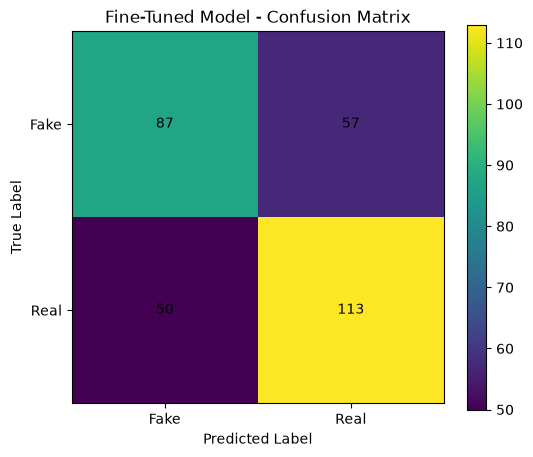

In [42]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

fine_cm = confusion_matrix(
    fine_all_labels,
    fine_all_predictions
)

print("Fine-Tuned Confusion Matrix:")
print(fine_cm)

plt.figure(figsize=(6, 5))

plt.imshow(fine_cm)

plt.title("Fine-Tuned Model - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks([0, 1], ["Fake", "Real"])
plt.yticks([0, 1], ["Fake", "Real"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            fine_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()